# Plotting

## Histology area quantification

[saved] /Users/Priya2/Documents/data/Immuno/Stroke_area_quantification.png


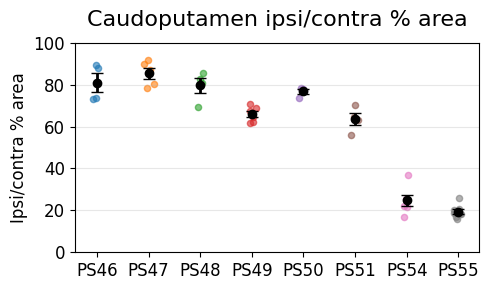

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

# =============================
# --------- KNOBS ------------
# =============================
TITLE_FONTSIZE = 16
AXIS_LABEL_FONTSIZE = 12
TICK_LABEL_FONTSIZE = 12

FIGSIZE = (5, 3)
TITLE_PAD = 12 

# Y-axis limits
Y_LIM = (0, 100)

# =============================
# --------- SAVE KNOBS -------
# =============================
SAVE_FIG = True
SAVE_DIR = "/Users/Priya2/Documents/data/Immuno"
SAVE_NAME = "Stroke area quantification"

# -----------------------------
# Data
# -----------------------------
data = {
    "PS46": [73.37, 73.27, 89.24, 88.09],
    "PS47": [90.05, 86.75, 80.13, 78.50, 91.89],
    "PS48": [82.78, 80.87, 85.73, 69.18],
    "PS49": [68.60, 64.52, 61.54, 62.28, 70.72, 67.41],
    "PS50": [73.47, 77.13, 78.06, 78.58],
    "PS51": [63.13, 64.58, 56.16, 70.11],
    "PS54": [37.09, 22.23, 16.91, 25.45, 21.55, 25.12],
    "PS55": [20.72, 20.35, 15.85, 16.96, 18.14, 26.10, 18.17, 18.80],
}

mice = list(data.keys())
x_positions = np.arange(len(mice))

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=FIGSIZE)

for i, mouse in enumerate(mice):
    y = np.array(data[mouse])

    # Jitter for visibility
    jitter = np.random.normal(0, 0.04, size=len(y))
    x = np.full_like(y, x_positions[i], dtype=float) + jitter

    # Scatter individual points
    plt.scatter(x, y, alpha=0.6, s=20)

    # Mean ± SEM
    mean = y.mean()
    sem = y.std(ddof=1) / np.sqrt(len(y))

    plt.errorbar(
        x_positions[i], mean, yerr=sem,
        fmt='o', color='black', capsize=4, linewidth=2, markersize=6, zorder=5
    )

# -----------------------------
# Formatting
# -----------------------------
plt.xticks(x_positions, mice, fontsize=TICK_LABEL_FONTSIZE)
plt.yticks(fontsize=TICK_LABEL_FONTSIZE)

plt.ylabel("Ipsi/contra % area", fontsize=AXIS_LABEL_FONTSIZE)
plt.title("Caudoputamen ipsi/contra % area", fontsize=TITLE_FONTSIZE, pad=TITLE_PAD)

plt.ylim(Y_LIM)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# -----------------------------
# Save figure
# -----------------------------
if SAVE_FIG:
    os.makedirs(SAVE_DIR, exist_ok=True)

    # Make filename filesystem-safe
    fname = SAVE_NAME.replace(" ", "_") + ".png"
    fpath = os.path.join(SAVE_DIR, fname)

    plt.savefig(fpath, dpi=300, bbox_inches="tight")
    print(f"[saved] {fpath}")

plt.show()


## Weights

[saved] /Users/Priya2/Documents/data/facerhythm_stroke_biomarker_exp/Stroke_weight_dm7_to_d21.png


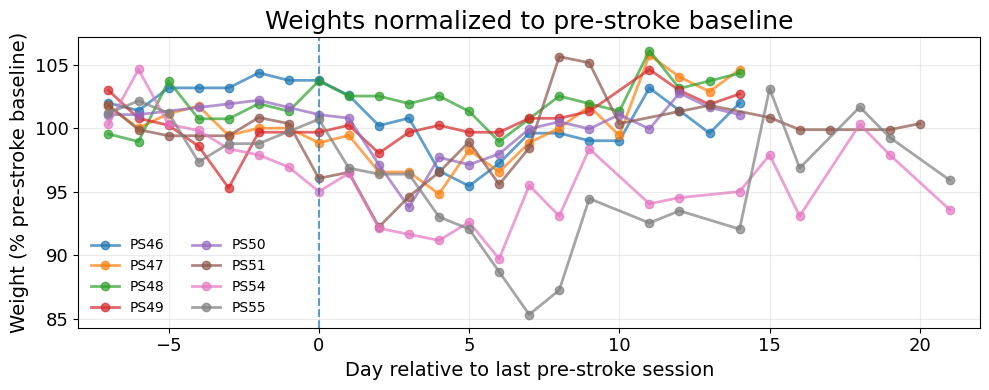

Baseline means (g):
  PS46: 16.867
  PS47: 17.400
  PS48: 16.777
  PS49: 18.259
  PS50: 17.810
  PS51: 20.925
  PS54: 20.838
  PS55: 20.854


In [4]:
import os
import re
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt

# =============================
# --------- KNOBS ------------
# =============================
FIGSIZE = (10, 4)

TITLE = "Weights normalized to pre-stroke baseline"
TITLE_FONTSIZE = 18
AXIS_LABEL_FONTSIZE = 14
TICK_LABEL_FONTSIZE = 13
LEGEND_FONTSIZE = 10

MARKER = "o"
LINEWIDTH = 2.0
MARKERSIZE = 6
ALPHA = 0.7

# Optional limits (set to None to autoscale)
Y_LIM = None  # e.g. (85, 105) or None
X_LIM = (-7, 21)       # e.g. (-10, 60)

# Padding (in days) added to each side when X_LIM is not None
X_LIM_PAD = 1     # e.g. 0.5–1.0 days looks nice

# =============================
# --------- SAVE KNOBS -------
# =============================
SAVE_FIG = True
SAVE_DIR = "/Users/Priya2/Documents/data/facerhythm_stroke_biomarker_exp"

# =============================
# Stroke anchor dates (d0 per mouse)
# =============================
stroke_dates_str = {
    "PS46": "2025-03-13",
    "PS47": "2025-03-13",
    "PS48": "2025-03-13",
    "PS49": "2025-03-17",
    "PS50": "2025-03-23",
    "PS51": "2025-04-29",
    "PS54": "2025-04-30",
    "PS55": "2025-04-30",
}
stroke_dates = {k: datetime.strptime(v, "%Y-%m-%d").date() for k, v in stroke_dates_str.items()}

# =============================
# Paste your table text here (as-is)
# =============================
raw = r"""
Weight (g)	PS46	PS47	PS48	PS49	PS50			PS51	PS54	PS55
2/26/25	16.1	17.6	16.4				4/16/25	20.5	20.3	20.4
2/27/25	16.4	17.8	16	19.1	18.1		4/17/25	20.8	20.3	20.4
2/28/25	16	17.4			17.7		4/18/25	20.8	20.6	20.5
3/1/25		17.1		18.3	17.4		4/19/25			
3/2/25	16.3			18.4	17.4		4/20/25			
3/3/25	16.2	16.8	16.4		17.3		4/21/25	22.2	22.6	21.9
3/4/25	16.4		16.4	18.3	17.3		4/22/25	21.3	21.8	21.1
3/5/25	16.5	17.2	16.9	18.3	17.3		4/23/25	20.9	20.9	21.1
3/6/25	17.2	17.7	16.7	18.4	17.3		4/24/25	20.8	21.8	21.3
3/7/25	17.1	17.4	16.6	18	17.5		4/25/25	20.8	20.9	21.1
3/8/25	17.4	17.6	17.4	18	17.8		4/26/25	20.8	20.8	20.3
3/9/25	17.4	17.7	16.9	18.1	18.2		4/27/25	21.1	20.5	20.6
3/10/25	17.4	17.3	16.9	18.8	18		4/28/25	21	20.4	20.6
3/11/25	17.6	17.4	17.1	18.4	18		4/29/25	20.1	20.2	20.8
3/12/25	17.5	17.4	17	18.3	18.1		4/30/25	20.2	19.8	21
3/13/25	17.5	17.2	17.4	18	17.9		5/1/25	19.3	20.1	20.2
3/14/25	17.3	17.3	17.2	17.4	17.5		5/2/25	19.8	19.2	20.1
3/15/25	16.9	16.8	17.2	18.2	18.1		5/3/25	20.2	19.1	20.1
3/16/25	17	16.8	17.1	18.2	18		5/4/25	20.7	19	19.4
3/17/25	16.3	16.5	17.2	18.2	18		5/5/25	20	19.3	19.2
3/18/25	16.1	17.1	17	18.3			5/6/25	20.6	18.7	18.5
3/19/25	16.4	16.8	16.6	17.9	18.1		5/7/25	22.1	19.9	17.8
3/20/25	16.8	17.2	16.9	18.2	18.15		5/8/25	22	19.4	18.2
3/21/25	16.8	17.4	17.2	18.3	18.2		5/9/25	21	20.5	19.7
3/22/25	16.7	17.7	17.1	18.2	18.1		5/10/25			
3/23/25	16.7	17.3	17	18.2	18		5/11/25	21.2	19.6	19.3
3/24/25	17.4	18.4	17.8	18.4	17.95		5/12/25	21.3	19.7	19.5
3/25/25	17.1	18.1	17.3	18.4	17.3		5/13/25			
3/26/25	16.8	17.9	17.4	18.5	16.7		5/14/25	21.1	19.8	19.2
3/27/25	17.2	18.2	17.5		17.4		5/15/25	20.9	20.4	21.5
3/28/25				19.1	17.3		5/16/25	20.9	19.4	20.2
3/29/25				18.8	17.45		5/17/25			
3/30/25				18.6	17.8		5/18/25	20.9	20.9	21.2
3/31/25				18.75	17.9		5/19/25	21	20.4	20.7
4/1/25					17.8		5/20/25			
4/2/25					18		5/21/25	21	19.5	20
4/3/25					17.8		5/22/25	21.2	20.3	19.9
4/4/25					18.3		5/23/25	21.4	19.9	20
4/5/25					18.1		5/24/25			
4/6/25					18		5/25/25			
							5/26/25	21.4	20	20.6
							5/27/25	21.7	20.1	20.2
							5/28/25	21.9	20.4	20.4
							5/29/25	21.3	20.3	20.5
							5/30/25	20.9	19.8	20.2
							5/31/25	21.1	19.8	19.8
							6/1/25	20.9	20.3	19.9
							6/2/25	20.9	19.9	20
							6/3/25	21.3	19.7	19.8
							6/4/25	20.9	20.9	20.8
							6/5/25	21.2	20.8	20.1
							6/6/25	21.5	20.9	19.9
							6/7/25	21.3	20.9	19.7
							6/8/25	20.75	20.9	19.6
							6/9/25	21	20.8	19.7
							6/10/25	20.8	21.1	20.1
							6/11/25	20.8	20.7	19.8
							6/12/25	20.8	20.4	19.9
							6/13/25	20.8	20.4	19.8
							6/14/25			
							6/15/25			
							6/16/25	21.4	21.6	20.5
							6/17/25	21	20.9	19.9
							6/18/25	20.5	20.9	20
							6/19/25	20.5	20.4	20.1
							6/20/25	21	20.7	20.1
							6/21/25	21.3	20.9	20.5
							6/22/25			
							6/23/25	21.1	20.9	20.8
							6/24/25	21.2	20.7	20.7
							6/25/25	21.2	21	20.6
							6/26/25	21.5	21.1	20.6
							6/27/25			
							6/28/25			
							6/29/25			
							6/30/25			
							7/1/25			
							7/2/25		21.7	
							7/3/25	22.9	21.6	21.4
							7/4/25			
							7/5/25			
							7/6/25			
							7/7/25			
							7/8/25			
							7/9/25	22.4	21.4	21
"""

# =============================
# Helpers
# =============================
date_pat = re.compile(r"^\s*(\d{1,2}/\d{1,2}/\d{2,4})\s*$")

def parse_us_date(s: str):
    s = s.strip()
    if not s:
        return None
    m, d, y = s.split("/")
    y = int(y)
    if y < 100:
        y += 2000
    return datetime(int(y), int(m), int(d)).date()

def to_float_or_none(x: str):
    x = x.strip()
    if x == "" or x.lower() == "nan":
        return None
    try:
        return float(x)
    except ValueError:
        return None

def make_xlim_suffix(xlim):
    if xlim is None:
        return "all"
    lo, hi = xlim
    def fmt(v):
        if v < 0:
            return f"m{abs(int(v))}"
        else:
            return f"{int(v)}"
    return f"d{fmt(lo)}_to_d{fmt(hi)}"


# =============================
# Parse the table into per-mouse series
# =============================
mice_left  = ["PS46", "PS47", "PS48", "PS49", "PS50"]
mice_right = ["PS51", "PS54", "PS55"]

# store as list of (date, weight)
series = {m: [] for m in stroke_dates.keys()}

for line in raw.splitlines():
    if not line.strip():
        continue
    if line.lower().startswith("weight"):
        continue

    cols = line.rstrip("\n").split("\t")

    # Left block
    left_date = parse_us_date(cols[0]) if cols[0].strip() else None
    if left_date is not None:
        for j, m in enumerate(mice_left, start=1):
            if j < len(cols):
                w = to_float_or_none(cols[j])
                if w is not None:
                    series[m].append((left_date, w))

    # Right block: find next date in row
    right_date = None
    right_date_idx = None
    for k in range(1, len(cols)):
        if date_pat.match(cols[k].strip()):
            right_date = parse_us_date(cols[k])
            right_date_idx = k
            break

    if right_date is not None and right_date_idx is not None:
        for offset, m in enumerate(mice_right, start=1):
            idx = right_date_idx + offset
            if idx < len(cols):
                w = to_float_or_none(cols[idx])
                if w is not None:
                    series[m].append((right_date, w))

# =============================
# Convert to day-relative, normalize, and plot
# =============================
plt.figure(figsize=FIGSIZE)

baseline_means = {}

for mouse, pts in series.items():
    if mouse not in stroke_dates:
        continue
    if len(pts) == 0:
        continue

    pts = sorted(pts, key=lambda x: x[0])

    d0 = stroke_dates[mouse]

    days = np.array([(d - d0).days for d, _ in pts], dtype=float)
    weights = np.array([w for _, w in pts], dtype=float)

    # ---- compute baseline: all days <= 0 (DO NOT window this) ----
    pre_mask = days <= 0
    if not np.any(pre_mask):
        print(f"[WARN] No pre-stroke data for {mouse}, skipping")
        continue

    baseline = weights[pre_mask].mean()
    baseline_means[mouse] = baseline
    weights_pct = 100.0 * weights / baseline

    # ---- window for plotting ONLY (blank outside X_LIM) ----
    if X_LIM is not None:
        lo, hi = X_LIM
        plot_mask = (days >= lo) & (days <= hi)
    else:
        plot_mask = np.ones_like(days, dtype=bool)

    days_plot = days[plot_mask]
    weights_pct_plot = weights_pct[plot_mask]

    # If nothing in-window, skip plotting this mouse
    if len(days_plot) == 0:
        continue

    plt.plot(
        days_plot, weights_pct_plot,
        marker=MARKER, linewidth=LINEWIDTH, markersize=MARKERSIZE,
        alpha=ALPHA, label=mouse
    )

# d0 reference
plt.axvline(0, linestyle="--", linewidth=1.5, alpha=0.7)

plt.title(TITLE, fontsize=TITLE_FONTSIZE)
plt.xlabel("Day relative to last pre-stroke session", fontsize=AXIS_LABEL_FONTSIZE)
plt.ylabel("Weight (% pre-stroke baseline)", fontsize=AXIS_LABEL_FONTSIZE)

plt.xticks(fontsize=TICK_LABEL_FONTSIZE)
plt.yticks(fontsize=TICK_LABEL_FONTSIZE)

if Y_LIM is not None:
    plt.ylim(Y_LIM)

if X_LIM is not None:
    lo, hi = X_LIM
    pad = X_LIM_PAD if X_LIM_PAD is not None else 0.0
    plt.xlim(lo - pad, hi + pad)

plt.grid(True, alpha=0.25)
plt.legend(fontsize=LEGEND_FONTSIZE, ncol=2, frameon=False)
plt.tight_layout()

# -----------------------------
# Save figure
# -----------------------------
if SAVE_FIG:
    os.makedirs(SAVE_DIR, exist_ok=True)

    suffix = make_xlim_suffix(X_LIM)
    fname = f"Stroke_weight_{suffix}.png"
    fpath = os.path.join(SAVE_DIR, fname)

    plt.savefig(fpath, dpi=300, bbox_inches="tight")
    print(f"[saved] {fpath}")

plt.show()

# Print baselines for sanity check
print("Baseline means (g):")
for k, v in baseline_means.items():
    print(f"  {k}: {v:.3f}")
